# EDA 14: chọn `eps` cho cluster_v2 (DBSCAN) và so với cluster_v1

Bước 6 của pipeline gom stay point thành địa điểm. v1 (`places/cluster_v1.py`) khoanh vòng tròn bán kính cố định quanh stay dài nhất; v2 (`places/cluster_v2.py`) loang dần, tức `DBSCAN(eps, min_samples=1)`: hai stay cùng một địa điểm nếu nối được qua chuỗi stay mà mỗi cặp liền kề cách nhau không quá `eps`. Mặc định v2 chỉ có **một** tham số là `eps` (`min_samples` = 1, không có ngưỡng giờ hay số stay tối thiểu, vì mỗi stay đã ≥ 30 phút (A14) và ngưỡng phiếu ở bước 7 (A11) lo phần còn lại). Mục 3 kiểm lại xem có cần nâng `min_samples` không.

Không có nhãn home/office (A13), nên **không dùng F1**. So sánh bằng các chỉ số không cần nhãn, cùng một bước bỏ phiếu (`home_office_conf.infer_user`) trên cùng bảng stay:

| Mục | Câu hỏi | Trình bày |
|---|---|---|
| 1 | Các stay của cùng một nơi home cách tâm nơi đó bao xa? (căn cứ cho `eps`) | bảng, hình |
| 2 | Khi quét `eps`, kết quả đổi thế nào so với v1 và với nhau? | bảng 2, hình |
| 3 | Quét `min_samples` ở `eps` đã chọn (D20): có cần ngưỡng số lần ghé không? | bảng 3 |
| 4 | Các ca đáng xem tay: home khác v1, gộp home với office mới xuất hiện | bảng 4a–4b |

**Hai lỗi đối nghịch cần cân nhau.** v1 hay **cắt đôi** một nơi (phiếu bị chia, confidence thấp giả tạo); v2 hay **gộp nhầm** hai nơi gần nhau (chaining). Eps nhỏ thì v2 giống v1 hơn; eps lớn thì cụm phình ra và dễ gộp.

**Định nghĩa các chỉ số:** "cùng chỗ" là hai tâm cách nhau ≤ `SAME_M` (hằng số ở `eda/place_eps.py`, quy ước của notebook, không phải ngưỡng pipeline). "Gộp mới" là `home_eq_office` ở v2 mà v1 không có. Lỗi cắt đôi của v1 không có chỉ số riêng; nó thể hiện qua số địa điểm giảm và confidence tăng khi `eps` lớn hơn.

> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).
>
> Cần chạy trước: `src/stays/detect.py` trên bản chia mới (stay `h1_mean`). Notebook tự gom cụm trong bộ nhớ, **không** ghi `places_v1` hay `places_v2`.

In [1]:
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import place_eps as pe
from eda import split
importlib.reload(pe)

USERS = None              # ví dụ ["000", "001", "002"] để chạy thử nhanh
EPS_LIST = pe.EPS_LIST    # mét

users = split.val_users()
if USERS:
    users = [u for u in users if u in set(USERS)]
R = pe.run(users, EPS_LIST)          # cache ở data/interim/eda_place_eps/; đổi code gom cụm hoặc stay thì xoá thư mục đó
print(f"{len(users)} user validation, {R['method'].nunique()} cách gom (v1 và eps = {EPS_LIST} m)")

20/115 user
40/115 user
60/115 user
80/115 user
100/115 user
115 user validation, 6 cách gom (v1 và eps = [100, 150, 200, 300, 500] m)


## 1. Các stay của cùng một nơi cách tâm bao xa

Lấy nơi home theo v1 của từng user, đo khoảng cách từ **mỗi stay thuộc nơi đó** đến tâm nơi đó. Đây là mức nhiễu vị trí mà một nơi thật tạo ra (GPS lệch, mỗi hôm ngồi một góc). Nếu gần hết dưới 100–150 m thì `eps` cỡ đó đã đủ nối một nơi; `eps` lớn hơn nhiều chỉ có tác dụng nối thêm nơi khác.

Hạn chế: nơi home của v1 bị cắt ở 200 m, nên khoảng cách không bao giờ vượt 200 m; phân bố này chỉ cho biết phần thân, không cho biết đuôi dài của các nơi rộng.

Bảng 1. Khoảng cách từ stay home đến tâm nơi home (v1), 2,454 stay của 100 user


,khoảng cách đến tâm home (m)
count,2454.0
mean,59.3
std,44.3
min,0.0
50%,48.2
75%,79.0
90%,120.9
95%,151.1
99%,196.0
max,275.4


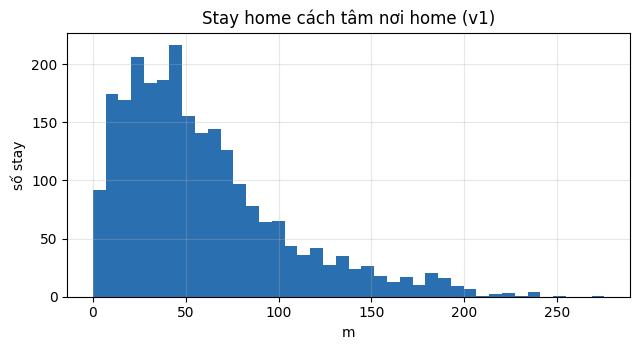

In [2]:
d = pe.stay_distances(R, "v1")
bang1 = d.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_frame("khoảng cách đến tâm home (m)")
print(f"Bảng 1. Khoảng cách từ stay home đến tâm nơi home (v1), {len(d):,} stay của {R[R['method'] == 'v1']['home'].notna().sum()} user")
display(bang1)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(d, bins=40, color="#2a6fb0")
ax.set_xlabel("m"); ax.set_ylabel("số stay"); ax.set_title("Stay home cách tâm nơi home (v1)")
ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

**Kết quả:** Trên 2.454 stay home của 100 user validation, khoảng cách đến tâm nơi home có trung vị 48,2 m, phân vị 90 là 120,9 m, phân vị 95 là 151,1 m, phân vị 99 là 196,0 m (lớn nhất 275,4 m). Vậy `eps` cỡ 150 m đã nối được khoảng 95% stay của một nơi, và 200 m phủ gần hết (khoảng 99%). Phân bố bị cắt ở 200 m vì cách gom của v1, nên đây chỉ là phần thân, không cho biết đuôi dài.

## 2. Quét `eps`

Mỗi dòng là một cách gom, tính trên toàn bộ user validation. Cột "cùng chỗ v1" là % user có home (hoặc office) cách tâm kết quả v1 ≤ `SAME_M`. Đường kính là khoảng cách xa nhất giữa hai stay trong nơi home; v1 bị giới hạn ở khoảng 400 m (hai đầu của vòng tròn 200 m), v2 thì không.

Cách đọc: tìm vùng `eps` mà các chỉ số gần như không đổi (vùng phẳng, như D16). Gộp mới tăng vọt hoặc đường kính phình ra nhanh là dấu hiệu `eps` đã quá lớn.

Bảng 2. So sánh các cách gom (validation)


cách gom,v1,eps100,eps150,eps200,eps300,eps500
user,115.0,115.0,115.0,115.0,115.0,115.0
số địa điểm (trung vị),11.0,13.0,11.0,10.0,8.0,7.0
home cùng chỗ v1 (%),100.0,94.0,94.0,93.0,91.0,88.0
home đổi so với v1 (user),0.0,6.0,6.0,7.0,9.0,12.0
office cùng chỗ v1 (%),100.0,100.0,100.0,100.0,96.2,94.0
home = office (user),30.0,26.0,32.0,33.0,34.0,36.0
gộp mới so với v1 (user),0.0,1.0,3.0,3.0,4.0,6.0
đường kính home trung vị (m),176.5,141.4,183.4,215.6,301.7,408.3
đường kính home p95 (m),333.1,467.7,681.6,798.2,1062.1,1676.1
đường kính home lớn nhất (m),397.7,708.2,987.3,1069.6,1608.4,2784.1


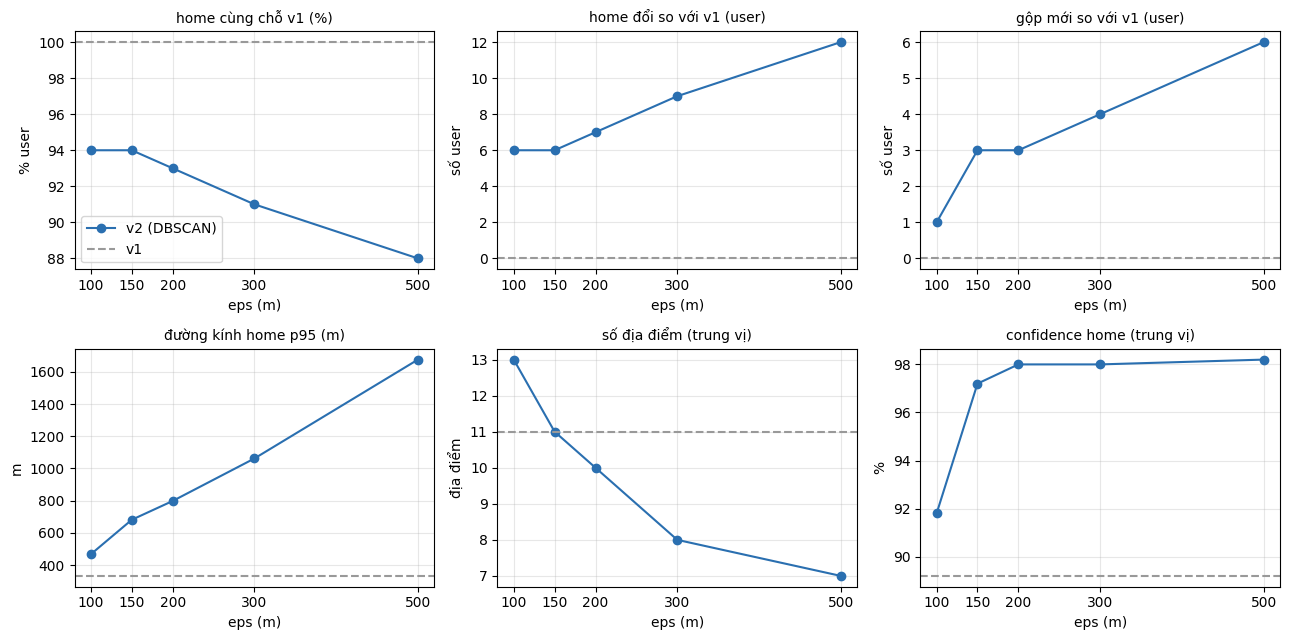

In [3]:
S = pe.compare(R)
print("Bảng 2. So sánh các cách gom (validation)")
display(S.round(1).T)
pe.plot(S); plt.show()

**Kết quả:** (115 user validation)

| | v1 | 100 | 150 | 200 | 300 | 500 |
|---|---|---|---|---|---|---|
| home đổi so với v1 (user) | 0 | 6 | 6 | 7 | 9 | 12 |
| gộp home với office mới (user) | 0 | 1 | 3 | 3 | 4 | 6 |
| đường kính home p95 (m) | 333 | 468 | 682 | 798 | 1.062 | 1.676 |
| confidence home (trung vị) | 89,2 | 91,8 | 97,2 | 98,0 | 98,0 | 98,2 |
| office cùng chỗ v1 (%) | 100 | 100 | 100 | 100 | 96,2 | 94,0 |

Từ `eps` = 150 trở lên confidence home gần như không tăng thêm (97,2 → 98,0 → 98,2), còn gộp mới, số home đổi và đường kính p95 tiếp tục tăng, nhanh nhất sau 200 m. Office không đổi ở `eps` ≤ 200 m. Độ ổn định home không đổi (0,8). Phần tăng confidence so với v1 một phần là cơ học (cụm gộp lại thì phiếu dồn về một nơi), nên **không** phải bằng chứng v2 đúng hơn v1. Dữ liệu cũng không phân biệt được 150 m và 200 m: cả hai đều gộp mới 3 user.

**Quyết định:** `eps` = 200 m. Đây là quy ước trong vùng 150–200 m, không phải giá trị tối ưu (không có nhãn, A13). Chọn 200 m vì trùng với D = 200 m (A14) và bán kính nơi của v1 (A15), nên v1 và v2 so với nhau cùng một thang. Chi phí của lựa chọn này: đường kính home p95 là 798 m, và có 3 user bị gộp home với office (mục 4b).

## 3. Quét `min_samples` ở `eps` đã chọn

`min_samples` đếm **số lần ghé** (số stay, gồm chính stay đó), như scikit-learn. Từ `min_samples` ≥ 2, stay không thuộc cụm nào là **nhiễu**: không thành địa điểm và không bỏ phiếu. Hai tác động ngược nhau: nâng `min_samples` có thể cắt cầu nối thưa (bớt gộp nhầm), nhưng nơi ghé ít lần bị loại (user ít dữ liệu có thể mất nơi thắng).

Cách đọc: chọn mức thấp nhất mà **gộp mới** giảm rõ so với `min_samples` = 1 và số user **mất** home / office chưa tăng. Nếu gộp mới không giảm thì giữ 1, vì thêm tham số mà không lợi gì. Mốc so sánh: cột "đổi / mất so với min_samples=1" lấy `min_samples` = 1 cùng `eps` làm chuẩn.

In [4]:
MS_LIST = pe.MS_LIST      # [1, 2, 3, 5]
R = pe.run(users, EPS_LIST, MS_LIST)       # chỉ tính thêm (eps = pe.EPS_MS, min_samples > 1); phần còn lại đọc từ cache
T3 = pe.compare_ms(R, pe.EPS_MS, MS_LIST)
print(f"Bảng 3. Quét min_samples ở eps = {pe.EPS_MS} m (validation)")
display(T3.round(1).T)

20/115 user
40/115 user
60/115 user
80/115 user
100/115 user
Bảng 3. Quét min_samples ở eps = 200 m (validation)


min_samples,1,2,3,5
user,115.0,115.0,115.0,115.0
số địa điểm (trung vị),10.0,3.0,2.0,1.0
stay nhiễu (%),0.0,20.4,28.1,36.0
giờ nhiễu (% trung vị theo user),0.0,10.7,20.1,31.0
home mất so với min_samples=1 (user),0.0,12.0,15.0,29.0
home đổi so với min_samples=1 (user),0.0,5.0,5.0,4.0
office mất so với min_samples=1 (user),0.0,6.0,9.0,18.0
office đổi so với min_samples=1 (user),0.0,0.0,0.0,2.0
home = office (user),33.0,33.0,34.0,32.0
gộp mới so với v1 (user),3.0,4.0,6.0,8.0


**Kết quả:** ở `eps` = 200 m, nâng `min_samples` lên 2, 3, 5 làm 20,4%, 28,1%, 36,0% stay thành nhiễu, số địa điểm trung vị giảm từ 10 xuống 3, 2, 1. Số user **mất** home là 12, 15, 29 và mất office là 6, 9, 18. Gộp mới không giảm mà tăng (3 → 4 → 6 → 8) và đường kính home p95 cũng không thu lại (798 → 833 → 841 → 867 m). Số user hết phiếu giảm (26 → 14 → 10 → 6); tôi chưa kiểm tra vì sao nên không dùng nó làm căn cứ.

**Quyết định:** giữ `min_samples` = 1 (D20). Nâng lên không cắt được cầu nối gộp nhầm mà lại làm mất home / office của nhiều user, vì phần lớn nơi chỉ ghé ít lần. Thêm tham số mà không lợi gì.

## 4. Các ca đáng xem tay

Chọn một `eps` để xem (đặt `EPS_VIEW`, mặc định lấy giá trị khởi điểm 200 m). Chỉ để hiểu nguyên nhân, không để chấm điểm.

- **4a.** User có home khác v1 (tâm cách nhau > `SAME_M`): v2 sửa lỗi cắt đôi hay làm lệch tâm?
- **4b.** User bị gộp home với office ở v2 mà v1 không bị: chaining.

In [5]:
EPS_VIEW = 200
m = f"eps{EPS_VIEW}"
print(f"Bảng 4a. Home khác v1 (eps = {EPS_VIEW} m)")
display(pe.differing(R, m, "home"))
print(f"Bảng 4a'. Office khác v1 (eps = {EPS_VIEW} m)")
display(pe.differing(R, m, "office"))
print(f"Bảng 4b. Gộp home với office mới so với v1 (eps = {EPS_VIEW} m)")
display(pe.merged(R, m))

Bảng 4a. Home khác v1 (eps = 200 m)


,cách nhau (m),địa điểm v1,địa điểm v2,home v1: nơi nhì (m),home v2: nơi nhì (m),home v2: đường kính (m),cờ v1,cờ v2
user,,,,,,,,
042,3785.0,49,45,15689.0,3785.0,288.0,unstable_home,unstable_home
083,2892.0,13,10,2880.0,2892.0,522.0,few_workdays;unstable_home,home_eq_office;few_workdays
078,456.0,16,15,470.0,456.0,300.0,home_eq_office;unstable_home,home_eq_office
101,446.0,23,20,929.0,1084.0,416.0,home_eq_office;unstable_home,home_eq_office
073,362.0,13,10,661.0,18169.0,881.0,,home_eq_office
007,285.0,38,31,632.0,2773.0,987.0,home_eq_office;unstable_home,home_eq_office
038,231.0,47,38,539.0,9647.0,1070.0,home_eq_office;unstable_home,home_eq_office


Bảng 4a'. Office khác v1 (eps = 200 m)


,cách nhau (m),địa điểm v1,địa điểm v2,office v1: nơi nhì (m),office v2: nơi nhì (m),office v2: đường kính (m),cờ v1,cờ v2
user,,,,,,,,


Bảng 4b. Gộp home với office mới so với v1 (eps = 200 m)


,n_places,home_diam_m,n_night_votes,n_work_votes,office v1 (place_id)
user,,,,,
073,10,880.766973,40.0,29.0,0.0
083,10,522.122513,10.0,4.0,3.0
179,18,340.941550,17.0,7.0,2.0


**Kết quả:** (115 user validation) với `eps` = 200 m và `min_samples` = 1:
- Home đổi so với v1 ở 7 user; office không đổi. Trong 7 user đó, 042 và 083 đổi sang nơi cách xa vài km, tôi chưa xem tay nên chưa biết v2 đúng hay sai.
- Confidence home (trung vị) từ 89,2 lên 98,0, phần lớn là hiệu ứng cơ học của việc gộp cụm.
- 3 user bị gộp home với office mà v1 không bị (073, 083, 179). User 073 là ca nối chuỗi rõ nhất (đường kính home 881 m).
- Đường kính home p95 là 798 m (v1: 333 m).

**Quyết định:** chốt `eps` = 200 m, `min_samples` = 1 cho `cluster_v2` (đã ghi ở D20 và A16). Hai bản v1 và v2 giữ song song, chưa kết luận bản nào tốt hơn. Nếu bước test cho thấy nối chuỗi là vấn đề lớn, hướng tiếp theo là HDBSCAN.